# Rich MIME Display Samples

Exercises every output path of the `typescript-bun` kernel: `display()` MIME bundles, `display_id` in-place updates, `[Symbol.for('Jupyter.display')]` rendering, stream capture, and `text/plain` fallbacks.

Run all cells top to bottom. Each output should render richly in the frontend.

In [2]:
// 1. text/plain bundle
display({ 'text/plain': 'Plain text MIME output from display().\nSecond line,\twith a tab.' });

Plain text MIME output from display().
Second line,	with a tab.

In [3]:
// 2. text/html bundle with inline CSS
const html = `
<div style="font-family: ui-sans-serif, system-ui, sans-serif; padding: 16px; border-radius: 12px; background: linear-gradient(135deg, #1e1b4b, #312e81 55%, #0f766e); color: #f8fafc; max-width: 560px;">
  <h2 style="margin: 0 0 8px; font-size: 20px;">text/html</h2>
  <p style="margin: 0 0 12px; color: #c7d2fe;">Rendered from an HTML MIME bundle with inline CSS.</p>
  <table style="border-collapse: collapse; width: 100%; font-size: 13px;">
    <thead>
      <tr style="text-align: left; color: #a5b4fc;">
        <th style="padding: 6px 8px; border-bottom: 1px solid #6366f1;">MIME</th>
        <th style="padding: 6px 8px; border-bottom: 1px solid #6366f1;">Status</th>
      </tr>
    </thead>
    <tbody>
      <tr><td style="padding: 6px 8px; border-bottom: 1px solid #3730a3;">text/html</td><td style="padding: 6px 8px; border-bottom: 1px solid #3730a3;">rich</td></tr>
      <tr><td style="padding: 6px 8px;">image/svg+xml</td><td style="padding: 6px 8px;">rich</td></tr>
    </tbody>
  </table>
</div>`;
display({ 'text/html': html });

MIME,Status
text/html,rich
image/svg+xml,rich


In [4]:
// 3. text/markdown bundle
display({
  'text/markdown': `## text/markdown

Markdown bundle rendered by the frontend.

- **Bold**, *italic*, \`inline code\`
- [Link](https://jupyter.org)

\`\`\`typescript
const answer: number = 42;
\`\`\`

| Column | Value |
| --- | ---: |
| alpha | 1 |
| beta | 2 |`,
});

## text/markdown

Markdown bundle rendered by the frontend.

- **Bold**, *italic*, `inline code`
- [Link](https://jupyter.org)

```typescript
const answer: number = 42;
```

| Column | Value |
| --- | ---: |
| alpha | 1 |
| beta | 2 |

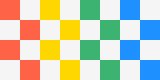

In [5]:
// 4. image/png bundle (160x80 checkerboard, tiny base64 payload)
display({
  'image/png':
    'iVBORw0KGgoAAAANSUhEUgAAAKAAAABQCAIAAAARP+ljAAAA8klEQVR42u3cMQ3AMAwEQCMJku4FEgRlUi4FUySdXQ62FGW46Pcf7kcrkfMs52u8fKOcTu/xXOV0esed5XR6AzBgwIABAwYMGDBgwIABAwYMGDBgwIABAwYMGDBgwIABAwYMGDBgwEuBW0jGsf04AAMGDBgwYMCAAQMGDBgwYMCAAQMGDBgwYMCAAQMGDBgwYMCAAQMGvBYYkqtKwIABAwYMGDBgwIABAwYMGDBgwIABAwYMGDBgwIABAwYMGDBgwIAB+yfLOFxVAgYMGDBgwIABAwYMGDBgwIABAwYMGDBgwIABAwYMGDBgwIABAwa8IfAPB164kS0RFJkAAAAASUVORK5CYII=',
  'text/plain': 'image/png: 160x80 checkerboard',
});

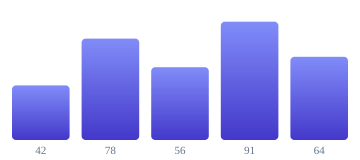

In [6]:
// 5. image/svg+xml bundle (generated bar chart)
const bars = [42, 78, 56, 91, 64];
const width = 360;
const height = 160;
const gap = 12;
const barWidth = (width - gap * (bars.length + 1)) / bars.length;
const rects = bars
  .map((value, i) => {
    const h = (value / 100) * (height - 30);
    const x = gap + i * (barWidth + gap);
    return `<rect x="${x}" y="${height - h - 20}" width="${barWidth}" height="${h}" rx="4" fill="url(#g)"/>`;
  })
  .join('');
const labels = bars
  .map((value, i) => {
    const x = gap + i * (barWidth + gap) + barWidth / 2;
    return `<text x="${x}" y="${height - 6}" text-anchor="middle" font-size="11" fill="#64748b">${value}</text>`;
  })
  .join('');
display({
  'image/svg+xml': `<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 ${width} ${height}" width="${width}" height="${height}"><defs><linearGradient id="g" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#818cf8"/><stop offset="1" stop-color="#4338ca"/></linearGradient></defs>${rects}${labels}</svg>`,
  'text/plain': 'image/svg+xml: bar chart',
});

In [7]:
// 6. text/latex bundle
display({
  'text/latex': '$$\\int_{-\\infty}^{\\infty} e^{-x^2}\\,dx = \\sqrt{\\pi}$$',
  'text/plain': 'integral from -inf to inf of e^(-x^2) dx = sqrt(pi)',
});

integral from -inf to inf of e^(-x^2) dx = sqrt(pi)

In [8]:
// 7. application/json bundle
display({
  'application/json': JSON.stringify(
    {
      kernel: 'typescript-bun',
      mime: 'application/json',
      nested: { array: [1, 2, 3], ok: true },
      unicode: 'pi ~ 3.14159',
    },
    null,
    2,
  ),
  'text/plain': 'application/json bundle (pretty-printed)',
});

application/json bundle (pretty-printed)

In [9]:
// 8. multi-MIME bundle: frontend picks the richest renderer
display({
  'text/html': '<b style="color:#0f766e">Preferred:</b> text/html wins when multiple MIME types are present.',
  'text/markdown': '**Preferred:** text/markdown fallback when HTML is unavailable.',
  'text/plain': 'Preferred: text/plain fallback when no rich renderer exists.',
});

Preferred: text/plain fallback when no rich renderer exists.

In [10]:
// 9. display_id + update: one output region updates in place
const displayId = 'progress-demo';
for (let i = 0; i <= 100; i += 20) {
  const filled = '#'.repeat(i / 10);
  const empty = '-'.repeat(10 - i / 10);
  await display(
    { 'text/html': `<pre style="margin:0">Progress [${filled}${empty}] ${i}%</pre>` },
    { display_id: displayId, update: i > 0 },
  );
  await new Promise((resolve) => setTimeout(resolve, 150));
}

Progress [##########] 100%

In [11]:
// 10. [Symbol.for('Jupyter.display')]: last expression renders as execute_result
class Gauge {
  constructor(private readonly value: number) {}

  [Symbol.for('Jupyter.display')]() {
    const percent = Math.round(this.value * 100);
    const color = this.value > 0.66 ? '#3cb371' : this.value > 0.33 ? '#ffd700' : '#ff6347';
    return {
      'text/html': `<div style="font-family: ui-sans-serif, system-ui, sans-serif; max-width: 420px;"><div style="display:flex; justify-content:space-between; font-size:13px; margin-bottom:4px;"><span>Symbol.for('Jupyter.display')</span><strong>${percent}%</strong></div><div style="height:14px; border-radius:7px; background:#e2e8f0; overflow:hidden;"><div style="width:${percent}%; height:100%; background:${color};"></div></div></div>`,
      'text/plain': `Gauge(${percent}%)`,
    };
  }
}

new Gauge(0.72);

Gauge(72%)

In [12]:
// 11. stream capture: stdout / stderr
console.log('stdout via console.log');
console.info('stdout via console.info');
console.warn('stderr via console.warn');
console.error('stderr via console.error');
process.stdout.write('raw stdout via process.stdout.write\n');
process.stderr.write('raw stderr via process.stderr.write\n');

stdout via console.log
stdout via console.info


stderr via console.warn
stderr via console.error


raw stdout via process.stdout.write


raw stderr via process.stderr.write


true

In [13]:
// 12. text/plain fallback with unicode and a long line
display({
  'text/plain': 'Unicode: \u65e5\u672c\u8a9e \u0627\u0644\u0639\u0631\u0628\u064a\u0629 \u03b5\u03bb\u03bb\u03b7\u03bd\u03b9\u03ba\u03ac \ud83c\udf89\nLong line: ' + 'x'.repeat(200),
});

Unicode: 日本語 العربية ελληνικά 🎉
Long line: xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

Done. Expected outputs: plain text, styled HTML card, Markdown block, checkerboard PNG, SVG bar chart, LaTeX formula, JSON tree, multi-MIME bundle, a progress bar that updates in place, a gauge rendered through `execute_result`, captured stdout/stderr streams, and unicode text.